# 使用 GLACIER 预测 MS/MS

在指定采集条件下预测分子的碎片质量和强度。

GLACIER 接收分子结构、加合物、碰撞能和仪器类型，通过碎片与强度预测模块生成 MS/MS 峰表。

本教程读取保存的预测，解释输入输出字段，并评估结果。最后给出在新数据集上运行模型的命令。

In [1]:
import json, sys, io
from pathlib import Path
from IPython.display import display, Markdown, SVG
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir()), None)
if root is None:
    raise RuntimeError('Run from the cloned release repository; see Quick Start')
sys.path.insert(0, str(root / 'scripts'))
from documentation_evidence import load_evidence, compact, recompute, render
from documentation_content import results_table
evidence = load_evidence('ms.forward.glacier')
print('Task:', evidence['task'])
print('Examples:', len(evidence['examples']))

Task: ms.forward.glacier
Examples: 3


## 输入与输出

| Field | Meaning |
| --- | --- |
| `smiles / adduct` | 分子结构与记录中的离子/加合物类型，例如 [M+H]+ 或 [M+Na]+。 |
| `collision_energy / instrument` | 模型支持的碰撞能与仪器条件。 |
| `precursor_mz` | 记录中的前体 m/z；按作者接口解释输入条件。 |

| Field | Meaning |
| --- | --- |
| `predicted_peaks` | m/z 与相对强度对；图中显示预测强度最高的 100 个峰。 |
| `similarity` | 与全部实测参考峰比较的余弦/熵相似度，同时统计跳过记录。 |

查看下面的示例记录。长数组显示长度与前几个数值，下载 JSON 可获取完整数组。

In [2]:
for example in evidence['examples'][:3]:
    print(json.dumps(compact(example), indent=2, ensure_ascii=False))

{
  "input": {
    "smiles": "C/C1=C\\[C@@H](C)C/C=C/[C@H]2[C@@H]3O[C@]3(C)[C@@H](C)[C@H]3[C@H](Cc4c[nH]c5ccccc45)NC(=O)[C@]32C(=O)/C=C/C(=O)[C@@H]1O",
    "adduct": "[M+Na]+",
    "collision_energy": "35.0",
    "instrument": "Orbitrap",
    "precursor_mz": 551.2511
  },
  "sample_id": "MassSpecGymID0000403",
  "output": {
    "predicted_peaks_top100": {
      "length": 100,
      "first_values": [
        [
          67.0542266590246,
          0.011822191998362541
        ],
        [
          81.06987672302459,
          0.16171321272850037
        ],
        [
          83.0491412790246,
          0.008260359987616539
        ],
        [
          83.0855267569754,
          0.0016736892284825444
        ],
        [
          89.038576431729,
          0.00573704531416297
        ],
        [
          91.051820956,
          0.012795776128768921
        ],
        [
          93.06987673804919,
          0.24028274416923523
        ],
        [
          95.04914129404919,
   

## 评估预测

使用余弦相似度与熵相似度比较预测谱和实测谱。

表格给出每次运行的数据集与指标。后续代码从绘图使用的预测值重新计算汇总结果。

In [3]:
display(Markdown(results_table(evidence, False)))
print(json.dumps(recompute(evidence), indent=2, ensure_ascii=False))

| Dataset / scope | Model / variant | Metric | Value |
| --- | --- | --- | ---: |
| recorded evaluation | recorded model | cosine_similarity | 0.485717 |
| recorded evaluation | recorded model | entropy_similarity | 0.41328 |


{
  "scope": "Saved model outputs are shown directly; aggregate metrics are in the run table.",
  "recorded_runs": 1,
  "real_examples": 3
}


## 查看结果图

实测与预测 MS/MS 谱。

比较预测与参考，查看返回的结构或峰位置。图由上方读取的记录直接生成。

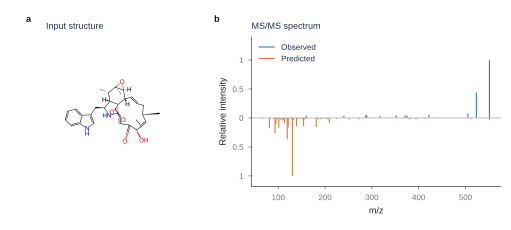

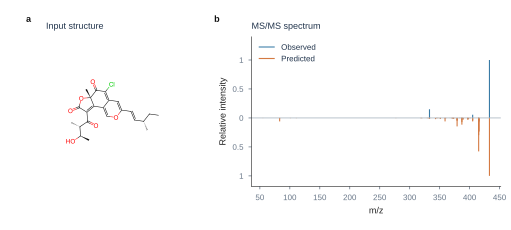

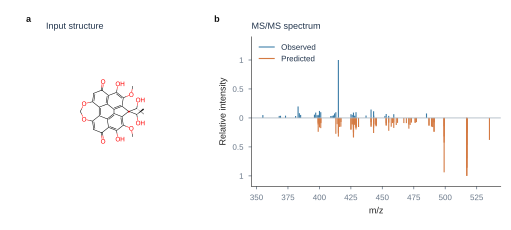

In [4]:
import matplotlib.pyplot as plt
for example_index in range(3):
    figure = render('ms.forward.glacier', evidence, example_index=example_index)
    image = io.StringIO()
    figure.savefig(image, format='svg', metadata={'Date': None})
    display(SVG(image.getvalue()))
    plt.close(figure)

## 运行模型

按任务指南配置环境和权重，在 benchmark runner 中选择本任务，即可评估自己的数据集。

```bash
python -m openmolspec_bench run --workspace /path/to/OpenMolSpec \
  --tasks ms.forward.glacier --limit 8 --output results/ms-forward-glacier.json
```

[Task](../tasks/ms-forward-glacier.md) · [Quick start](../quickstart.md)



## 参考文献

- Wang, R.-X., Wang, R. & Coley, C. W. GLACIER: Rethinking Mass Spectrum Prediction as an Object Detection Problem. NeurIPS 2026. arXiv:2606.29161 (2026). [Source](https://arxiv.org/abs/2606.29161)
- Bushuiev, R., Bushuiev, A., de Jonge, N. F., Young, A., et al. MassSpecGym: A benchmark for the discovery and identification of molecules. Advances in Neural Information Processing Systems 37, Datasets and Benchmarks Track (2024). arXiv:2410.23326. [Source](https://arxiv.org/abs/2410.23326)
